In [184]:
import pandas as pd
from sklearn import preprocessing
from tensorboard.plugins import scalar

In [185]:
# file_path = '../input/credit_card_fraud_detection_500k.csv'
file_path = '../input/creditcard.csv'
df = pd.read_csv(file_path)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [186]:
df.shape

(284807, 31)

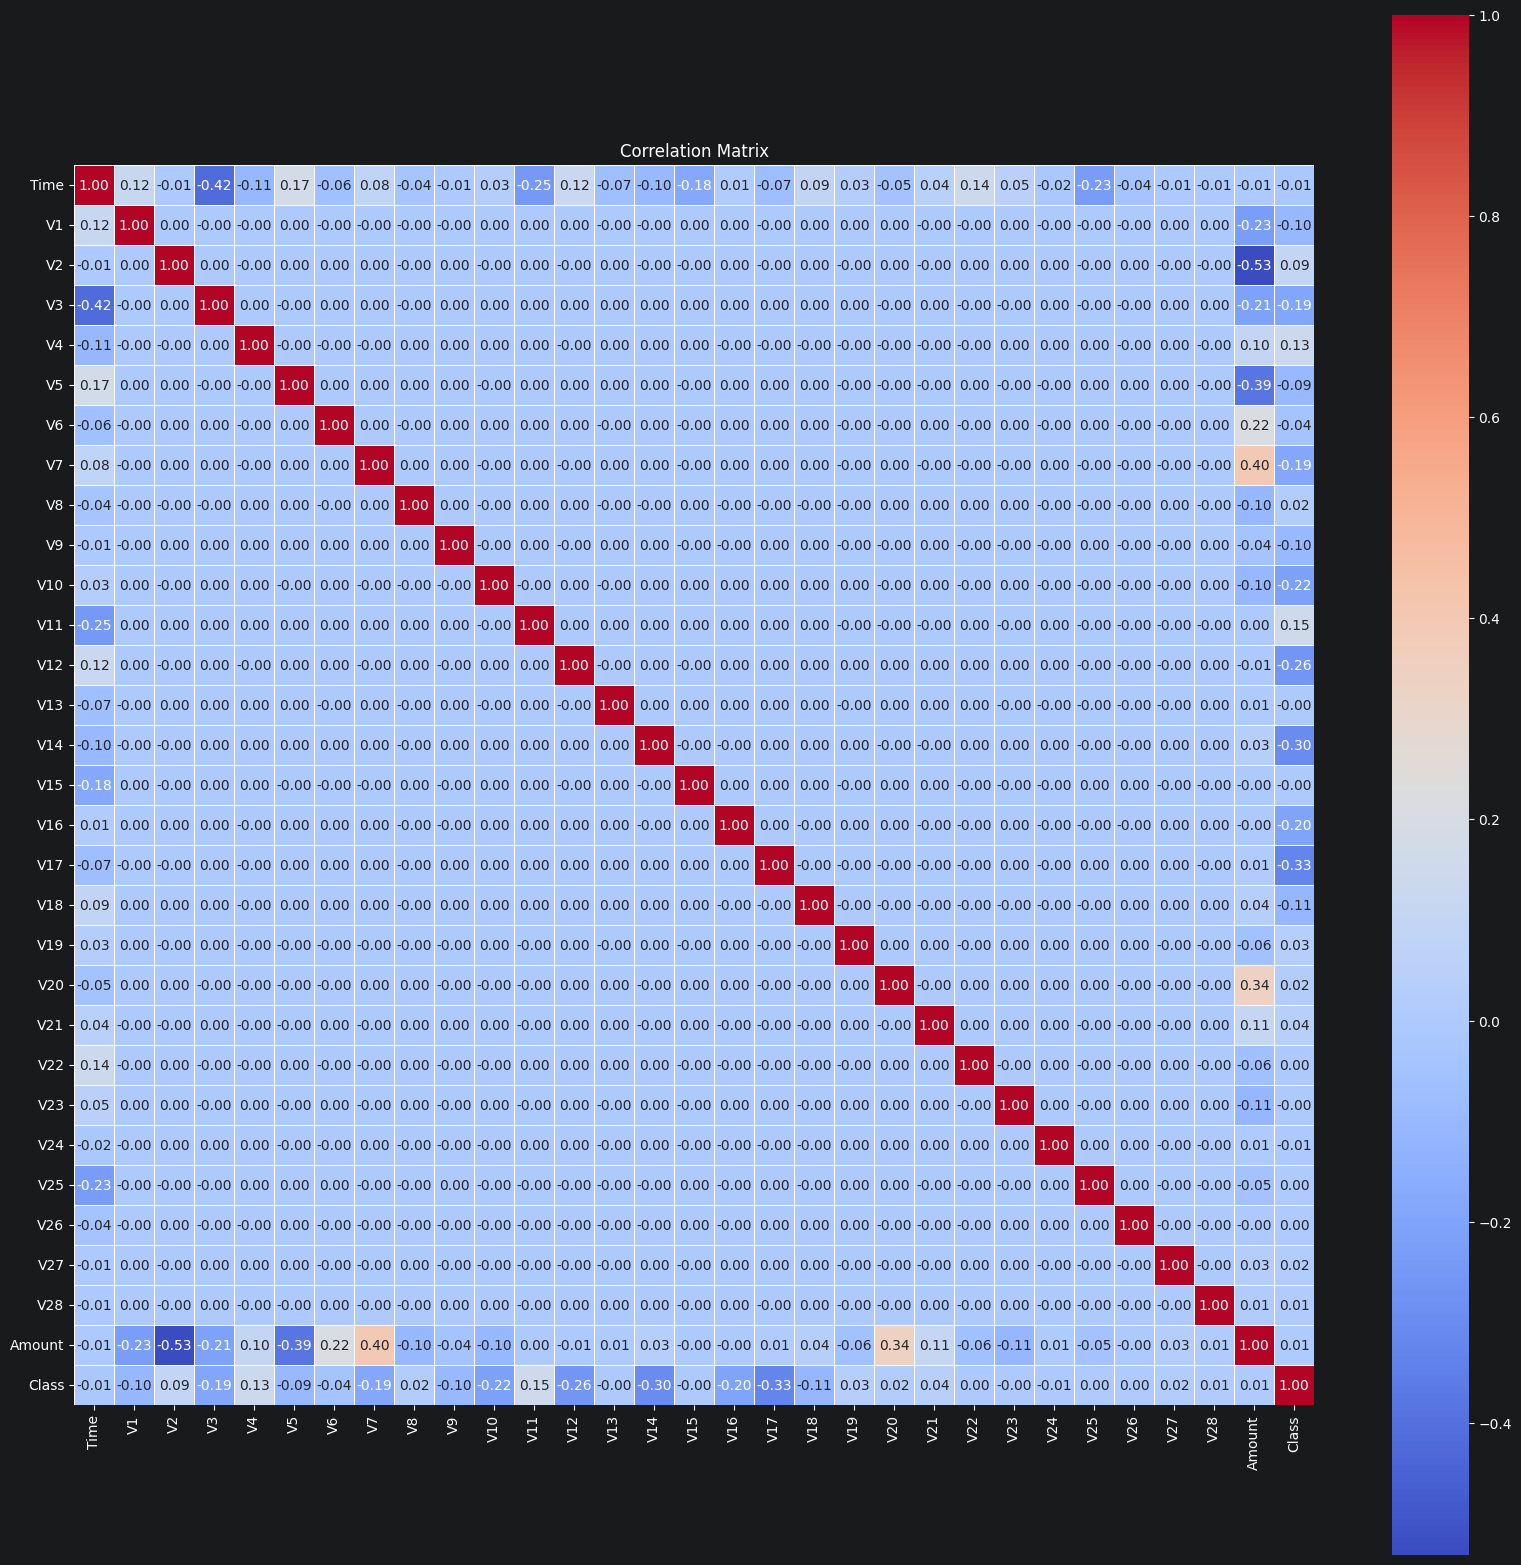

In [187]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. සහසම්බන්ධතාවය ගණනය කිරීම
corr = df.corr(numeric_only=True)

# 2. ප්‍රස්ථාරයේ ප්‍රමාණය තීරණය කිරීම
plt.figure(figsize=(20, 20))

# 3. Seaborn Heatmap එක ඇඳීම
# annot=True මඟින් කොටු ඇතුළත අගයන් (0.85, -0.23 ආදී) පෙන්වයි
# fmt=".2f" මඟින් දශම ස්ථාන 2කට අගයන් සීමා කරයි
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)

plt.title('Correlation Matrix')
plt.show()


In [188]:
print(len(df.columns))
print(df.columns)

31
Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


In [189]:
# Step 1 — Data Preprocessing
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [190]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [192]:
# # 1. 'transaction_time' තීරුව Pandas datetime ආකෘතියට පත් කිරීම
# df['transaction_time'] = pd.to_datetime(df['transaction_time'])
#
# # 2. පැය (Hour: 0–23) ලබාගෙන අලුත් තීරුවක් සෑදීම
# df['transaction_hour'] = df['transaction_time'].dt.hour
#
# # 3. සතියේ දිනය (Day of Week: 0–6) ලබාගෙන අලුත් තීරුවක් සෑදීම (0 = සඳුදා, 6 = ඉරිදා)
# df['transaction_day_of_week'] = df['transaction_time'].dt.dayofweek

In [193]:
# drop_list = ['transaction_id','customer_id','transaction_time']
# df.drop(columns=drop_list, inplace=True)

In [194]:
# df.shape

In [195]:
X = df.drop('Class',axis=1)
X.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'],
      dtype='object')

In [196]:
y = df['Class']
# ratios = y.value_counts(normalize=True)
# ratio_1_to_0 = ratios[1] / ratios[0]
# print(f"\nRatio of 1 to 0: {ratio_1_to_0:.2f}:1")
# print(ratios)

In [197]:
# import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# from sklearn.compose import ColumnTransformer, make_column_selector
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer

# cat_preprocessing = Pipeline(steps=[
#     ('impute', SimpleImputer(strategy='most_frequent')),
#     ('encode', OneHotEncoder(handle_unknown='ignore',sparse_output=False))
# ])
#
# num_preprocessing = Pipeline(steps=[
#     ('impute', SimpleImputer(strategy='median')),
#     ('scale', StandardScaler())
# ])
#
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', num_preprocessing, make_column_selector(dtype_include=['int64', 'float64'])),
#         ('cat', cat_preprocessing, make_column_selector(dtype_include=['object', 'category']))
#     ]
#     ,
#     remainder='passthrough'
# )

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)



X_train, X_test, y_train,y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(y_train.shape)

(227845, 30)
(227845,)


In [198]:
X_train

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
223361,1.022112,0.998136,-0.230595,-0.207758,0.233183,-0.369046,-0.064700,-0.507624,0.030137,0.959887,...,-0.162649,0.324289,1.334304,0.085207,-0.460007,-0.086325,-0.449541,0.111905,-0.142827,-0.313289
165061,0.470837,-0.204716,-0.379665,1.025778,-1.425115,-0.078079,0.126334,0.014517,-0.336266,0.036753,...,-0.610140,-0.208959,0.581097,0.181664,-1.657891,-2.257331,0.750528,-0.917839,-0.438653,-0.169717
238186,1.152945,0.037019,0.496919,-0.370223,-0.501387,0.782760,-0.269788,0.636863,0.098192,-0.119490,...,0.015860,-0.428357,-1.202920,0.133541,0.244662,-0.827696,0.248202,0.511344,0.212940,-0.305292
150562,-0.024087,-0.273165,0.614415,1.154609,1.955969,0.362319,0.752303,0.685400,-0.068090,0.338220,...,-0.329160,0.086485,0.611038,-0.116507,0.740024,-1.256918,-0.375422,-0.230441,-0.196713,0.116306
138452,-0.256040,-2.055932,1.149012,-0.283453,-0.020886,-0.620000,-0.360593,-0.352142,1.099978,0.487920,...,-0.015981,-0.654427,-0.317444,0.401495,0.109633,0.903141,0.508756,0.710805,-0.977550,-0.250239
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,-0.404225,0.599118,0.061038,0.323503,0.326017,-0.214728,-0.160001,-0.133583,0.099821,-0.103946,...,-0.204344,-0.253262,-0.791350,0.258472,-0.010138,0.175424,0.226522,-0.051835,0.012020,-0.345313
259178,1.351627,-0.396173,0.087218,-0.753436,-0.876575,1.405808,2.936401,-0.376776,1.139213,0.364724,...,-0.383604,0.050479,-0.026974,0.387264,1.127424,-3.136737,-1.598712,0.163531,0.415216,0.003520
131932,-0.316266,-0.074850,0.601310,1.005500,0.343093,0.253077,-0.611887,0.870300,-0.330988,-0.447196,...,0.009281,0.071678,0.487927,-0.466320,0.665156,0.455388,-0.826308,-0.300123,-0.594382,-0.337477
146867,-0.144939,-1.505412,1.426053,-1.662785,-2.683097,1.352153,2.047406,-0.381353,1.856688,0.528112,...,0.541423,-0.453028,-1.443453,0.229520,1.120901,0.613320,0.884044,1.231103,1.017386,-0.349231


In [199]:
# Step 2: Model Building
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input

model = Sequential([
    Input(shape=(30,)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(8, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
model.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_48 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [200]:
# Step 3: Model Compiling & Training
import tensorflow as tf

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy',tf.keras.metrics.AUC(name='auc'),tf.keras.metrics.Precision(name='precision'),tf.keras.metrics.Recall(name='recall')])

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Info සහ Warning messages ඉවත් කරයි


In [201]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weight_array = compute_class_weight(
    class_weight = 'balanced',
    classes = classes,
    y = y_train
)
class_weight_dict = dict(zip(classes,class_weight_array))

custom_class_weight_dict = {
    0: 1,
    1: 10
}
print("computed Class Weights:", class_weight_dict)
print("custom Class Weights:", custom_class_weight_dict)

computed Class Weights: {np.int64(0): np.float64(0.5008661206149896), np.int64(1): np.float64(289.14340101522845)}
custom Class Weights: {0: 1, 1: 10}


In [202]:
import datetime
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard

# 1. EarlyStopping Callback එක සකස් කිරීම
# මෙහිදී 'val_loss' එක වට 5ක් (patience=5) පුරා අඩු නොවුණහොත් පුහුණුව ස්වයංක්‍රීයව නවතී
early_stopping = EarlyStopping(
    monitor='val_auc',
    patience=7,
    restore_best_weights=True  # හොඳම ප්‍රතිඵල ලැබුණු වටයේ බර (weights) මොඩලයට ඉතිරි කරයි
)

# 2. TensorBoard Callback එක සකස් කිරීම (ප්‍රස්ථාර බැලීමට)
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)


# 3. Model Train (model.fit)
history = model.fit(
    X_train, y_train,
    batch_size=1024,
    epochs=30,
    validation_split=0.2,
    class_weight=custom_class_weight_dict,
    callbacks=[early_stopping, tensorboard_callback],
    verbose=1
)
results = model.evaluate(X_test, y_test)
print("Test Results:", results)


Epoch 1/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9719 - auc: 0.7993 - loss: 0.1779 - precision: 0.0240 - recall: 0.3916 - val_accuracy: 0.9994 - val_auc: 0.9574 - val_loss: 0.0038 - val_precision: 0.8353 - val_recall: 0.8353
Epoch 2/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9984 - auc: 0.9379 - loss: 0.0422 - precision: 0.5188 - recall: 0.7605 - val_accuracy: 0.9993 - val_auc: 0.9692 - val_loss: 0.0048 - val_precision: 0.7742 - val_recall: 0.8471
Epoch 3/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9986 - auc: 0.9539 - loss: 0.0346 - precision: 0.5688 - recall: 0.7896 - val_accuracy: 0.9991 - val_auc: 0.9753 - val_loss: 0.0051 - val_precision: 0.7184 - val_recall: 0.8706
Epoch 4/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9989 - auc: 0.9700 - loss: 0.0284 - precision: 0.6458 - recall: 0.8026 - val_accuracy: 0.9986 - val_auc: 0.9804 - val_loss: 0.0069 - val_precision: 0.5906 - val_recall: 0.8824
Epoch 5/30
179/179 ━━━━━━━━━━━━━

In [204]:
# y_pred_proba = model.predict(X_test_preprocessed)
#
# print(f"Min Probability : {np.min(y_pred_proba):.4f}")
# print(f"Max Probability: {np.max(y_pred_proba):.4f}")
# print(f"Mean Probability: {np.mean(y_pred_proba):.4f}")